# 01 - Analisis Data Eksploratif (EDA) Penjualan Retail

Notebook ini adalah langkah pertama analisis: memahami bentuk data, memeriksa hasil pembersihan, dan menemukan pola besar sebelum masuk ke analisis yang lebih spesifik (segmentasi RFM di notebook 02 dan uji A/B di notebook 03).

**Dataset**: Online Retail II (UCI Machine Learning Repository) - transaksi sebuah peritel online berbasis Inggris yang sebagian besar pelanggannya adalah pembeli grosir, periode 1 Desember 2009 sampai 9 Desember 2011.

**Pertanyaan yang ingin dijawab di notebook ini**

1. Seberapa besar data yang hilang akibat pembersihan, dan mengapa?
2. Bagaimana tren pendapatan bulanan dan seberapa kuat musimannya?
3. Seperti apa distribusi nilai keranjang (apakah rata-rata representatif)?
4. Produk, kategori, dan negara mana yang mendominasi?
5. Kapan transaksi terjadi (hari dan jam)?
6. Seberapa besar masalah retur dan di kategori mana?

Semua angka di sini dihitung langsung dari data bersih (`data/processed/retail_clean.parquet`) yang dihasilkan oleh `src/data/clean.py`.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebook dijalankan dari folder notebooks/, sehingga akar proyek adalah satu tingkat di atas.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import ASSETS_DIR, CLEAN_PARQUET, RAW_CSV, WAREHOUSE_DB  # noqa: E402
from src.data.clean import RETURNS_PARQUET  # noqa: E402
from src.viz import CATEGORY_COLORS, CATEGORY_ORDER, INK_MUTED, INK_SECONDARY, SEQUENTIAL, SERIES, apply_matplotlib_style, gbp  # noqa: E402

apply_matplotlib_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

sales = pd.read_parquet(CLEAN_PARQUET)
returns = pd.read_parquet(RETURNS_PARQUET)

# Kategori dan deskripsi baku diambil dari dim_product di warehouse agar angka di
# notebook ini identik dengan hasil query SQL (satu kode stok = satu kategori).
with sqlite3.connect(WAREHOUSE_DB) as conn:
    dim_product = pd.read_sql("SELECT stock_code, description AS product_name, category FROM dim_product", conn)
sales = sales.merge(dim_product, on="stock_code", how="left")
returns = returns.merge(dim_product, on="stock_code", how="left")
print(f"Baris penjualan : {len(sales):,}")
print(f"Baris retur     : {len(returns):,}")
print(f"Rentang tanggal : {sales['invoice_date'].min()} s.d. {sales['invoice_date'].max()}")

Baris penjualan : 1,003,214
Baris retur     : 17,914
Rentang tanggal : 2009-12-01 07:45:00 s.d. 2011-12-09 12:50:00


## 1. Struktur data bersih

Setiap baris adalah satu item dalam satu invoice (grain: *invoice line*). Kolom `line_total` = `quantity` x `unit_price`, `is_guest` menandai baris tanpa ID pelanggan, dan `category` ditetapkan dari kata kunci deskripsi produk.

In [2]:
display(sales.head())
print(sales.dtypes)
display(sales[["quantity", "unit_price", "line_total"]].describe(percentiles=[0.5, 0.9, 0.99]).T)

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet,is_return,line_total,is_guest,invoice_month,product_name,category
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,Year 2009-2010,False,83.40,False,2009-12,15CM CHRISTMAS GLASS BALL 20 LIGHTS,Christmas & Seasonal
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010,False,81.00,False,2009-12,PINK CHERRY LIGHTS,Home Decor
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010,False,81.00,False,2009-12,WHITE CHERRY LIGHTS,Home Decor
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,Year 2009-2010,False,100.80,False,2009-12,"RECORD FRAME 7"" SINGLE SIZE",Home Decor
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,Year 2009-2010,False,30.00,False,2009-12,STRAWBERRY CERAMIC TRINKET BOX,Home Decor


invoice_no               string
stock_code               object
description              string
quantity                  int64
invoice_date     datetime64[us]
unit_price              float64
customer_id               Int64
country                  string
source_sheet                str
is_return                  bool
line_total              float64
is_guest                   bool
invoice_month               str
product_name                str
category                    str
dtype: object


,count,mean,std,min,50%,90%,99%,max
quantity,"1,003,214.00",11.15,128.75,1.00,4.00,24.00,108.00,"80,995.00"
unit_price,"1,003,214.00",3.34,4.75,0.03,2.10,7.62,16.95,"1,157.15"
line_total,"1,003,214.00",19.58,200.00,0.06,10.08,32.85,179.00,"168,469.60"


## 2. Dampak pembersihan data

Membandingkan jumlah baris mentah dengan hasil bersih memperlihatkan seberapa banyak data yang dibuang dan karena alasan apa. Aturan lengkapnya ada di `src/data/clean.py`; di sini kita hitung ulang tiap kategori pembuangan supaya transparan.

In [3]:
raw = pd.read_csv(RAW_CSV, dtype={"invoice_no": "string", "stock_code": "string"}, usecols=["invoice_no", "stock_code", "description", "quantity", "invoice_date", "unit_price", "customer_id", "country"])
n_raw = len(raw)
n_dup = raw.duplicated().sum()
dedup = raw.drop_duplicates()
non_product = ~dedup["stock_code"].str.strip().str.upper().str.match(r"^\d{5}[A-Za-z]{0,3}$").fillna(False)
after_prod = dedup[~non_product]
bad_price = (after_prod["unit_price"] <= 0) | after_prod["description"].isna()
after_price = after_prod[~bad_price]
is_cancel = after_price["invoice_no"].str.startswith("C")
stock_adj = (after_price["quantity"] < 0) & ~is_cancel

ringkasan = pd.DataFrame(
    {
        "tahap": ["Baris mentah", "Duplikat persis", "Kode non-produk (POST, M, D, ...)", "Harga <= 0 / deskripsi kosong", "Penyesuaian stok (qty < 0 tanpa 'C')", "Retur (dipisah)", "Penjualan bersih"],
        "baris": [n_raw, -n_dup, -int(non_product.sum()), -int(bad_price.sum()), -int(stock_adj.sum()), len(returns), len(sales)],
    }
)
ringkasan["persen_dari_mentah"] = (100 * ringkasan["baris"] / n_raw).round(2)
display(ringkasan)
print(f"Baris tanpa ID pelanggan pada penjualan bersih: {sales['is_guest'].mean():.1%} baris, {sales.loc[sales['is_guest'], 'line_total'].sum() / sales['line_total'].sum():.1%} pendapatan")

,tahap,baris,persen_dari_mentah
0,Baris mentah,1067371,100.00
1,Duplikat persis,-34335,-3.22
2,"Kode non-produk (POST, M, D, ...)",-5980,-0.56
3,Harga <= 0 / deskripsi kosong,-5928,-0.56
4,Penyesuaian stok (qty < 0 tanpa 'C'),0,0.00
5,Retur (dipisah),17914,1.68
6,Penjualan bersih,1003214,93.99


Baris tanpa ID pelanggan pada penjualan bersih: 22.6% baris, 13.1% pendapatan


**Catatan**: sekitar 23% baris tidak memiliki ID pelanggan. Baris ini tetap dipertahankan sebagai *pelanggan tamu* karena merupakan penjualan nyata; hanya analisis per pelanggan (RFM, cohort) yang mengecualikannya.

## 3. KPI utama

Pendapatan bersih = penjualan kotor dikurangi nilai retur. AOV (*average order value*) dihitung per invoice penjualan.

In [4]:
gross = sales["line_total"].sum()
returned = -returns["line_total"].sum()
invoices = sales["invoice_no"].nunique()
kpi = pd.Series(
    {
        "Pendapatan kotor (GBP)": gross,
        "Nilai retur (GBP)": returned,
        "Pendapatan bersih (GBP)": gross - returned,
        "Tingkat retur (% nilai)": 100 * returned / gross,
        "Jumlah invoice penjualan": invoices,
        "Jumlah invoice retur": returns["invoice_no"].nunique(),
        "Pelanggan terdaftar": sales["customer_id"].nunique(),
        "Produk terjual (kode stok)": sales["stock_code"].nunique(),
        "Unit terjual": sales["quantity"].sum(),
        "AOV (GBP per invoice)": gross / invoices,
        "Median nilai invoice (GBP)": sales.groupby("invoice_no")["line_total"].sum().median(),
    }
)
display(kpi.to_frame("nilai"))

,nilai
Pendapatan kotor (GBP),"19,642,692.15"
Nilai retur (GBP),"716,425.97"
Pendapatan bersih (GBP),"18,926,266.18"
Tingkat retur (% nilai),3.65
Jumlah invoice penjualan,"39,516.00"
Jumlah invoice retur,"7,405.00"
Pelanggan terdaftar,"5,852.00"
Produk terjual (kode stok),"4,707.00"
Unit terjual,"11,187,774.00"
AOV (GBP per invoice),497.08


## 4. Tren pendapatan bulanan

Garis per tahun memudahkan membandingkan bulan yang sama antar tahun. Desember 2011 hanya berisi 9 hari data sehingga ditampilkan sebagai titik terbuka dan tidak boleh dibaca sebagai penurunan.

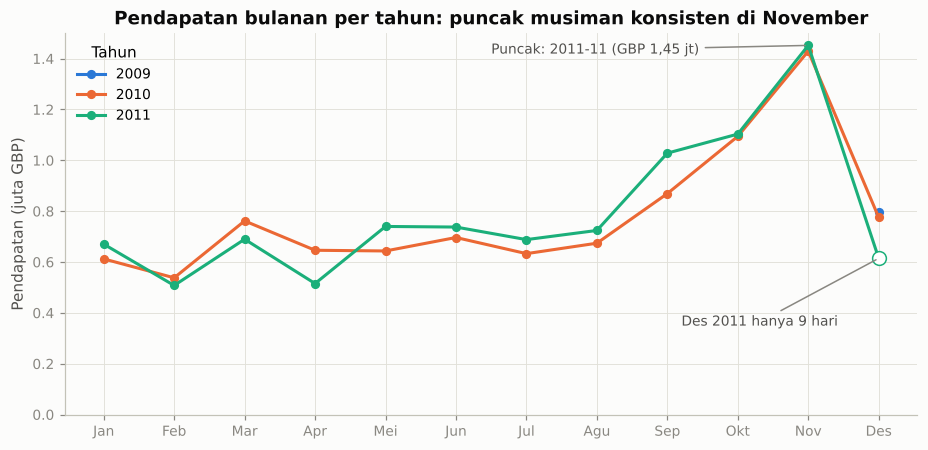

year,2009,2010,2011
month,,,
1,NaN,"612,271.00","670,362.00"
2,NaN,"537,894.00","507,783.00"
3,NaN,"761,666.00","689,708.00"
4,NaN,"646,233.00","515,355.00"
5,NaN,"643,474.00","739,914.00"
6,NaN,"696,439.00","737,559.00"
7,NaN,"632,984.00","688,145.00"
8,NaN,"674,037.00","724,197.00"
9,NaN,"869,224.00","1,028,314.00"


In [5]:
monthly = sales.groupby(sales["invoice_date"].dt.to_period("M")).agg(revenue=("line_total", "sum"), invoices=("invoice_no", "nunique")).reset_index()
monthly["year"] = monthly["invoice_date"].dt.year
monthly["month"] = monthly["invoice_date"].dt.month
monthly["invoice_date"] = monthly["invoice_date"].astype(str)

fig, ax = plt.subplots(figsize=(10, 4.5))
month_labels = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
for i, (year, grp) in enumerate(monthly.groupby("year")):
    ax.plot(grp["month"], grp["revenue"] / 1e6, marker="o", markersize=5, color=SERIES[i], label=str(year))
partial = monthly[monthly["invoice_date"] == "2011-12"]
ax.plot(partial["month"], partial["revenue"] / 1e6, marker="o", markersize=9, markerfacecolor="white", color=SERIES[2], linestyle="none")
ax.annotate("Des 2011 hanya 9 hari", xy=(12, partial["revenue"].iloc[0] / 1e6), xytext=(9.2, 0.35), color=INK_SECONDARY, fontsize=9, arrowprops={"arrowstyle": "-", "color": INK_MUTED})
peak = monthly.loc[monthly["revenue"].idxmax()]
ax.annotate(f"Puncak: {peak['invoice_date']} ({gbp(peak['revenue'])})", xy=(peak["month"], peak["revenue"] / 1e6), xytext=(6.5, 1.42), color=INK_SECONDARY, fontsize=9, arrowprops={"arrowstyle": "-", "color": INK_MUTED})
ax.set_xticks(range(1, 13), month_labels)
ax.set_ylabel("Pendapatan (juta GBP)")
ax.set_ylim(0)
ax.set_title("Pendapatan bulanan per tahun: puncak musiman konsisten di November")
ax.legend(title="Tahun", loc="upper left")
fig.savefig(ASSETS_DIR / "eda_tren_bulanan.png")
plt.show()

monthly["revenue"] = monthly["revenue"].round(0)
display(monthly.pivot(index="month", columns="year", values="revenue"))

## 5. Distribusi nilai keranjang per invoice

Nilai invoice sangat miring ke kanan (beberapa pesanan grosir bernilai puluhan ribu pound). Karena itu median jauh di bawah rata-rata, dan uji statistik pada rata-rata (notebook 03) perlu metode yang tahan terhadap kemiringan (Welch + bootstrap).

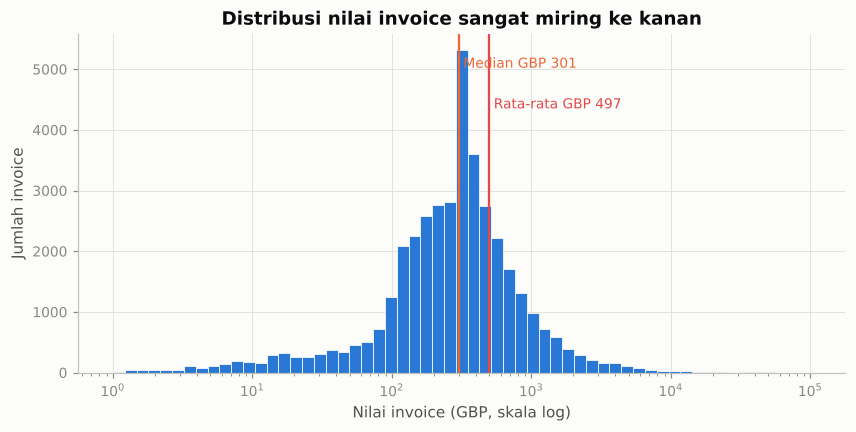

,count,mean,std,min,25%,50%,75%,90%,99%,max
value,"39,516.00",497.08,"1,460.30",0.19,150.32,301.23,484.40,905.56,"4,103.92","168,469.60"
units,"39,516.00",283.12,"1,204.01",1.00,67.00,148.00,289.00,523.00,"2,224.00","87,167.00"
lines,"39,516.00",25.10,42.24,1.00,6.00,15.00,28.00,51.00,196.85,"1,106.00"


In [6]:
basket = sales.groupby("invoice_no").agg(value=("line_total", "sum"), units=("quantity", "sum"), lines=("stock_code", "nunique"))
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(0, 5, 60)
ax.hist(basket["value"], bins=bins, color=SERIES[0], edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.axvline(basket["value"].median(), color=SERIES[1], linewidth=1.5)
ax.axvline(basket["value"].mean(), color=SERIES[7], linewidth=1.5)
ax.text(basket["value"].median() * 1.08, ax.get_ylim()[1] * 0.9, f"Median {gbp(basket['value'].median(), 0)}", color=SERIES[1], fontsize=9)
ax.text(basket["value"].mean() * 1.08, ax.get_ylim()[1] * 0.78, f"Rata-rata {gbp(basket['value'].mean(), 0)}", color=SERIES[7], fontsize=9)
ax.set_xlabel("Nilai invoice (GBP, skala log)")
ax.set_ylabel("Jumlah invoice")
ax.set_title("Distribusi nilai invoice sangat miring ke kanan")
fig.savefig(ASSETS_DIR / "eda_distribusi_keranjang.png")
plt.show()
display(basket.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).T)

## 6. Produk dan kategori

Peringkat produk memakai **pendapatan bersih** (penjualan dikurangi retur). Ini penting karena ada satu pesanan 80.995 unit "PAPER CRAFT, LITTLE BIRDIE" yang dibatalkan di hari yang sama; jika memakai penjualan kotor, produk itu akan muncul palsu di peringkat 4.

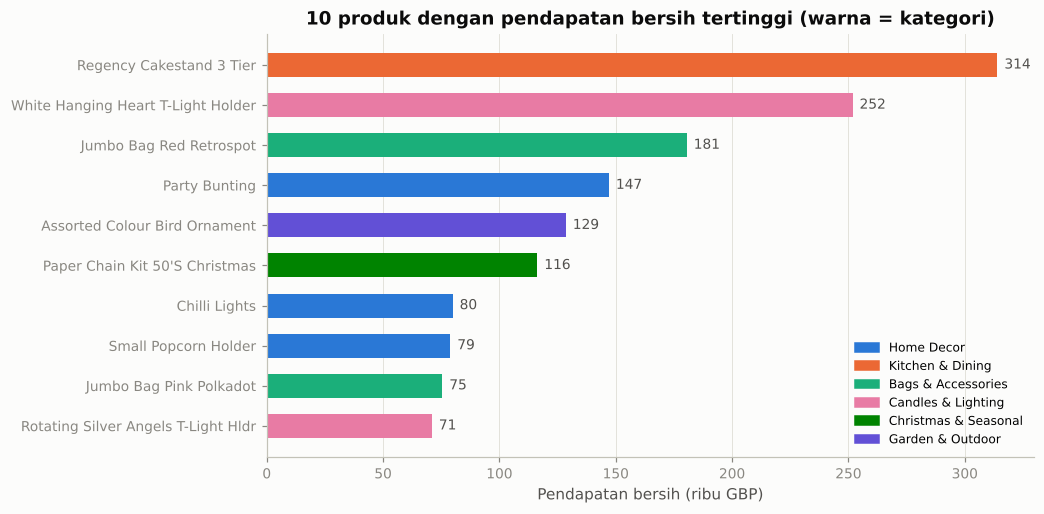

,stock_code,product_name,category,net_revenue,units
0,22423,REGENCY CAKESTAND 3 TIER,Kitchen & Dining,"314,045.02",26478
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,Candles & Lighting,"251,781.63",94719
2,85099B,JUMBO BAG RED RETROSPOT,Bags & Accessories,"180,512.16",97176
3,47566,PARTY BUNTING,Home Decor,"147,079.73",28200
4,84879,ASSORTED COLOUR BIRD ORNAMENT,Garden & Outdoor,"128,550.42",80082
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,Christmas & Seasonal,"116,298.59",35084
6,79321,CHILLI LIGHTS,Home Decor,"79,905.13",15841
7,22197,SMALL POPCORN HOLDER,Home Decor,"78,903.62",88499
8,22386,JUMBO BAG PINK POLKADOT,Bags & Accessories,"75,457.64",39437
9,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,Candles & Lighting,"70,969.95",31409


In [7]:
net = pd.concat([sales, returns]).groupby(["stock_code", "product_name", "category"]).agg(net_revenue=("line_total", "sum")).reset_index()
units = sales.groupby("stock_code")["quantity"].sum().rename("units")
net = net.merge(units, on="stock_code").sort_values("net_revenue", ascending=False)
top10 = net.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5))
colors = [CATEGORY_COLORS[c] for c in top10["category"]]
ax.barh(top10["product_name"].str.title(), top10["net_revenue"] / 1e3, color=colors, height=0.6)
for y, (val, cat) in enumerate(zip(top10["net_revenue"], top10["category"])):
    ax.text(val / 1e3 + 3, y, f"{val / 1e3:,.0f}", va="center", fontsize=9, color=INK_SECONDARY)
ax.set_xlabel("Pendapatan bersih (ribu GBP)")
ax.set_title("10 produk dengan pendapatan bersih tertinggi (warna = kategori)")
handles = [plt.Rectangle((0, 0), 1, 1, color=CATEGORY_COLORS[c]) for c in CATEGORY_ORDER if c in set(top10["category"])]
ax.legend(handles, [c for c in CATEGORY_ORDER if c in set(top10["category"])], loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
fig.savefig(ASSETS_DIR / "eda_top_produk.png")
plt.show()
display(net.head(10).reset_index(drop=True))

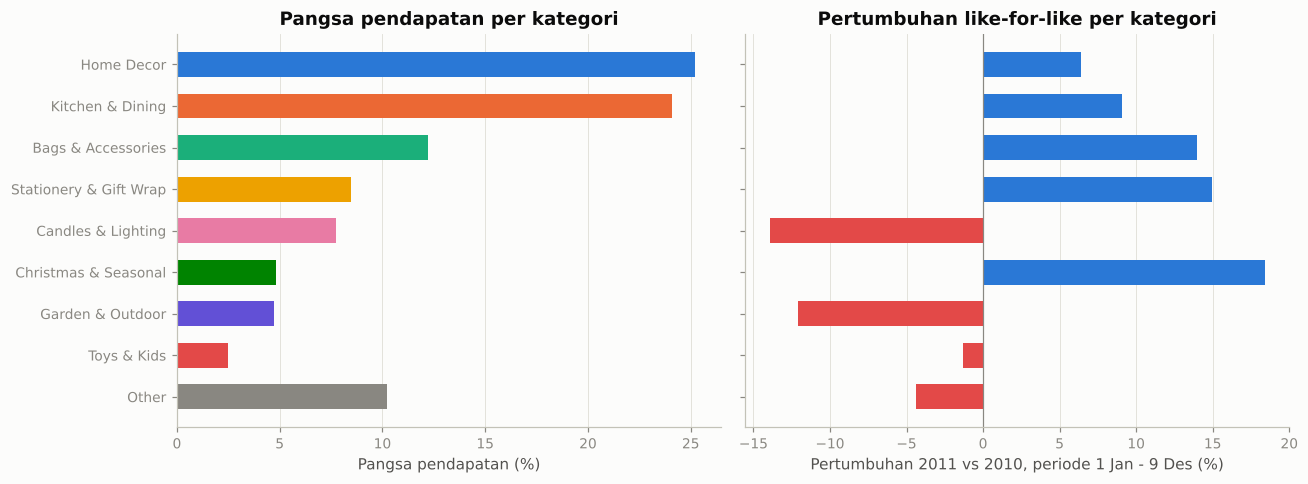

,revenue,share_pct,growth_lfl_pct
category,,,
Home Decor,"4,953,858.65",25.22,6.40
Kitchen & Dining,"4,735,294.71",24.11,9.05
Bags & Accessories,"2,404,227.39",12.24,13.98
Stationery & Gift Wrap,"1,663,169.55",8.47,14.95
Candles & Lighting,"1,519,831.30",7.74,-13.93
Christmas & Seasonal,"943,432.59",4.80,18.38
Garden & Outdoor,"930,582.53",4.74,-12.09
Toys & Kids,"488,740.15",2.49,-1.28
Other,"2,003,555.28",10.20,-4.37


In [8]:
sales["year"] = sales["invoice_date"].dt.year
same_window = sales[(sales["invoice_date"].dt.month * 100 + sales["invoice_date"].dt.day) <= 1209]  # 1 Jan - 9 Des tiap tahun
cat = sales.groupby("category")["line_total"].sum().rename("revenue").to_frame()
cat["share_pct"] = 100 * cat["revenue"] / cat["revenue"].sum()
lfl = same_window[same_window["year"].isin([2010, 2011])].pivot_table(index="category", columns="year", values="line_total", aggfunc="sum")
cat["growth_lfl_pct"] = 100 * (lfl[2011] - lfl[2010]) / lfl[2010]
cat = cat.loc[CATEGORY_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(cat.index[::-1], cat["share_pct"][::-1], color=[CATEGORY_COLORS[c] for c in cat.index[::-1]], height=0.6)
axes[0].set_xlabel("Pangsa pendapatan (%)")
axes[0].set_title("Pangsa pendapatan per kategori")
axes[0].grid(axis="y", visible=False)
growth = cat["growth_lfl_pct"][::-1]
axes[1].barh(growth.index, growth, color=[SERIES[0] if v >= 0 else SERIES[7] for v in growth], height=0.6)
axes[1].axvline(0, color=INK_MUTED, linewidth=0.8)
axes[1].set_xlabel("Pertumbuhan 2011 vs 2010, periode 1 Jan - 9 Des (%)")
axes[1].set_title("Pertumbuhan like-for-like per kategori")
axes[1].grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.tight_layout()
fig.savefig(ASSETS_DIR / "eda_kategori.png")
plt.show()
display(cat.round(2))

## 7. Negara

Pasar domestik (UK) mendominasi, tetapi pelanggan luar negeri berbelanja dalam pesanan yang jauh lebih besar per invoice.

,revenue,invoices,customers,share_pct,aov
country,,,,,
United Kingdom,"16,799,849.90",36184,5334,85.53,464.29
EIRE,"623,414.16",581,3,3.17,"1,073.00"
Netherlands,"549,773.41",216,22,2.80,"2,545.25"
Germany,"383,289.00",753,107,1.95,509.02
France,"311,090.29",598,93,1.58,520.22
Australia,"167,800.01",89,15,0.85,"1,885.39"
Spain,"97,766.75",144,38,0.50,678.94
Switzerland,"94,024.59",85,22,0.48,"1,106.17"
Sweden,"86,319.14",99,19,0.44,871.91


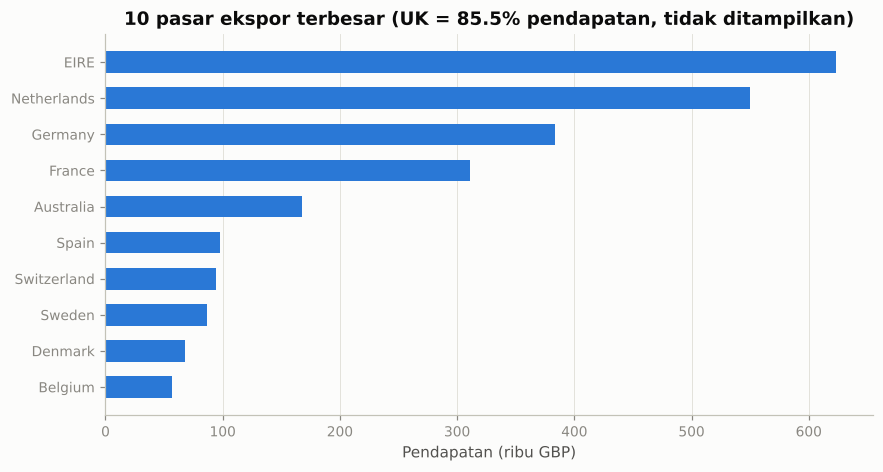

In [9]:
country = sales.groupby("country").agg(revenue=("line_total", "sum"), invoices=("invoice_no", "nunique"), customers=("customer_id", "nunique")).sort_values("revenue", ascending=False)
country["share_pct"] = 100 * country["revenue"] / country["revenue"].sum()
country["aov"] = country["revenue"] / country["invoices"]
display(country.head(12).round(2))

top_ex = country.drop("United Kingdom").head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top_ex.index, top_ex["revenue"] / 1e3, color=SERIES[0], height=0.6)
ax.set_xlabel("Pendapatan (ribu GBP)")
ax.set_title(f"10 pasar ekspor terbesar (UK = {country.loc['United Kingdom', 'share_pct']:.1f}% pendapatan, tidak ditampilkan)")
ax.grid(axis="y", visible=False)
fig.savefig(ASSETS_DIR / "eda_negara.png")
plt.show()

## 8. Pola hari dan jam transaksi

Heatmap jumlah invoice per hari dan jam memakai satu warna (biru) dari terang ke gelap: semakin gelap, semakin banyak invoice.

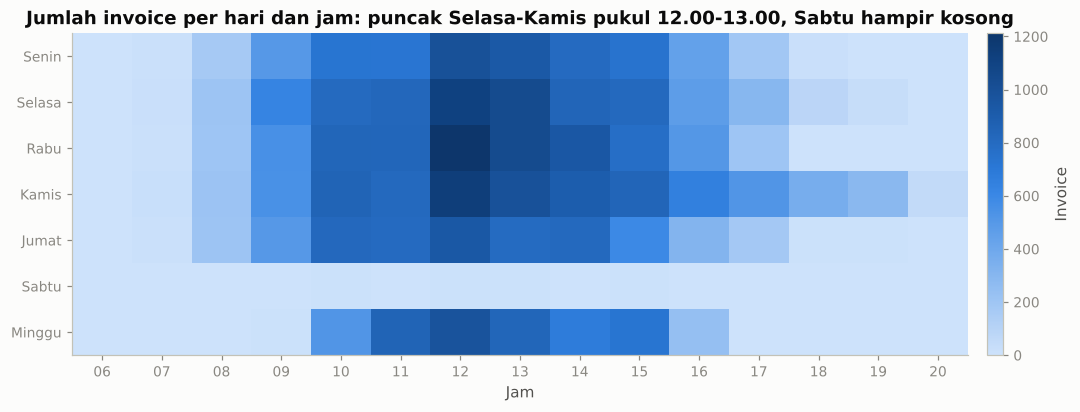

Invoice per hari:
dow
Senin     6245
Selasa    7147
Rabu      7115
Kamis     8167
Jumat     5988
Sabtu       30
Minggu    4824


In [10]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list("blue_seq", SEQUENTIAL)
inv = sales.drop_duplicates("invoice_no")
heat = inv.assign(dow=inv["invoice_date"].dt.dayofweek, hour=inv["invoice_date"].dt.hour).pivot_table(index="dow", columns="hour", values="invoice_no", aggfunc="count", fill_value=0)
heat = heat.reindex(range(7), fill_value=0)
day_names = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, cmap=cmap, aspect="auto")
ax.set_yticks(range(7), day_names)
ax.set_xticks(range(len(heat.columns)), [f"{h:02d}" for h in heat.columns])
ax.set_xlabel("Jam")
ax.set_title("Jumlah invoice per hari dan jam: puncak Selasa-Kamis pukul 12.00-13.00, Sabtu hampir kosong")
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Invoice")
fig.savefig(ASSETS_DIR / "eda_heatmap_hari_jam.png")
plt.show()
print("Invoice per hari:")
print(heat.sum(axis=1).rename(index=dict(enumerate(day_names))).to_string())

## 9. Retur per kategori

Retur diukur sebagai persentase nilai penjualan. Kategori dengan basis kecil (< GBP 100 ribu) diabaikan agar persentase tidak liar.

In [11]:
ret_cat = pd.DataFrame({"gross": sales.groupby("category")["line_total"].sum(), "returned": -returns.groupby("category")["line_total"].sum()}).fillna(0)
ret_cat["return_rate_pct"] = 100 * ret_cat["returned"] / ret_cat["gross"]
ret_cat["return_invoices"] = returns.groupby("category")["invoice_no"].nunique()
# Versi tanpa pesanan anomali 80.995 unit yang dibatalkan di hari yang sama.
anomaly = returns[returns["stock_code"] == "23843"]["line_total"].sum()
ret_cat.loc["Stationery & Gift Wrap", "return_rate_excl_anomaly_pct"] = 100 * (ret_cat.loc["Stationery & Gift Wrap", "returned"] + anomaly) / (ret_cat.loc["Stationery & Gift Wrap", "gross"] + anomaly)
display(ret_cat.sort_values("return_rate_pct", ascending=False).round(2))
print(f"Tingkat retur keseluruhan: {100 * ret_cat['returned'].sum() / ret_cat['gross'].sum():.2f}% dari nilai penjualan")

,gross,returned,return_rate_pct,return_invoices,return_rate_excl_anomaly_pct
category,,,,,
Stationery & Gift Wrap,"1,663,169.55","195,685.01",11.77,629,1.82
Kitchen & Dining,"4,735,294.71","218,240.57",4.61,3401,NaN
Candles & Lighting,"1,519,831.30","45,685.89",3.01,1156,NaN
Home Decor,"4,953,858.65","124,781.92",2.52,2690,NaN
Toys & Kids,"488,740.15","11,908.14",2.44,327,NaN
Other,"2,003,555.28","42,260.39",2.11,1375,NaN
Garden & Outdoor,"930,582.53","17,579.82",1.89,566,NaN
Bags & Accessories,"2,404,227.39","44,005.47",1.83,1078,NaN
Christmas & Seasonal,"943,432.59","16,278.76",1.73,471,NaN


Tingkat retur keseluruhan: 3.65% dari nilai penjualan


## 10. Ringkasan temuan EDA

Angka di bawah diambil dari keluaran sel-sel di atas.

1. **Pembersihan membuang 6,0% baris mentah** (1.067.371 -> 1.003.214 baris penjualan + 17.914 baris retur). Penyumbang terbesar adalah duplikat persis (34.335 baris; termasuk tumpang tindih 1-9 Desember 2010 yang muncul di kedua sheet sumber), lalu kode non-produk seperti ongkos kirim dan penyesuaian manual (5.980), dan baris berharga nol (5.928). Sekitar 22,6% baris tidak memiliki ID pelanggan (13,1% pendapatan) dan dipertahankan sebagai pelanggan tamu.
2. **Skala bisnis**: pendapatan kotor GBP 19,64 juta, retur GBP 0,72 juta (3,65%), pendapatan bersih GBP 18,93 juta dari 39.516 invoice dan 5.852 pelanggan terdaftar. AOV GBP 497, tetapi **median invoice hanya GBP 301** - rata-rata ditarik ke atas oleh pesanan grosir besar (persentil 99 = GBP 4.104).
3. **Musiman sangat kuat dan berulang**: November adalah puncak di kedua tahun (GBP 1,43 juta pada 2010; GBP 1,45 juta pada 2011), sekitar 2,7 kali bulan terendah (Februari 2011, GBP 0,51 juta). Kenaikan dimulai sejak September karena pengecer menyetok barang Natal.
4. **Produk**: tidak ada produk yang menyumbang lebih dari 1,7% pendapatan. "REGENCY CAKESTAND 3 TIER" memimpin lewat harga (GBP 314 ribu bersih, harga rata-rata GBP 14), sedangkan "WHITE HANGING HEART T-LIGHT HOLDER" (GBP 252 ribu) dan "JUMBO BAG RED RETROSPOT" (GBP 181 ribu) memimpin lewat volume (95-97 ribu unit).
5. **Kategori**: Home Decor (25,2%) dan Kitchen & Dining (24,1%) menyumbang hampir separuh pendapatan. Pada periode yang disamakan (1 Jan - 9 Des), Christmas & Seasonal (+18,4%), Stationery & Gift Wrap (+15,0%), dan Bags & Accessories (+14,0%) tumbuh, sementara Candles & Lighting (-13,9%) dan Garden & Outdoor (-12,1%) menyusut.
6. **Negara**: UK menyumbang 85,5% pendapatan. Pelanggan ekspor jauh lebih besar per pesanan - AOV Belanda GBP 2.545 dan Australia GBP 1.936 vs UK GBP 464.
7. **Waktu transaksi**: puncak pukul 12.00-13.00 pada Selasa-Kamis; Kamis adalah hari tersibuk (~8,2 ribu invoice) dan Sabtu praktis kosong (30 invoice) - pola khas sistem pemesanan B2B yang tidak beroperasi di akhir pekan.
8. **Retur**: 3,65% dari nilai penjualan. Angka 11,8% pada Stationery & Gift Wrap hampir seluruhnya berasal dari satu pesanan 80.995 unit yang dibatalkan di hari yang sama (tanpa itu 1,8%); masalah retur yang nyata ada di Kitchen & Dining (4,6% nilai, 3.389 invoice retur), kemungkinan karena barang pecah belah rusak saat pengiriman.

Temuan ini menjadi dasar untuk notebook berikutnya: segmentasi pelanggan (02) dan uji perbandingan periode musim puncak (03).